# Assignment 5 - S1 Defensive Quality Compounder

This notebook implements **Strategy S1: Defensive Quality Compounder** as a standalone backtest.

The strategy follows a screening waterfall rather than a single opaque score:

1. require enough trailing return history;
2. remove stocks with large trading gaps;
3. remove illiquid stocks;
4. require recent lagged fundamental data;
5. require positive profitability;
6. avoid highly leveraged firms;
7. avoid high realized volatility;
8. require at least median quality among the remaining stocks;
9. allocate capital with a long-only minimum-variance optimizer.

All accounting/fundamental screens use a 90-day reporting lag. Portfolio returns are simulated net of the assignment costs: **1% fixed cost per year** and **0.2% transaction cost per rebalancing**.

## 1. Imports and Paths

In [1]:
# Standard library imports
import os
import sys
from pathlib import Path

# Keep matplotlib cache inside a writable folder when running in restricted environments.
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

# Third party imports
import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt


def find_course_root(start=None):
    """Find the qpmwp-course folder from common notebook working directories."""
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / 'data' / 'market_data.parquet').exists() and (candidate / 'src').exists():
            return candidate
        nested = candidate / 'qpmwp-course'
        if (nested / 'data' / 'market_data.parquet').exists() and (nested / 'src').exists():
            return nested
    raise FileNotFoundError('Could not locate qpmwp-course from the current working directory.')


COURSE_ROOT = find_course_root()
DATA_PATH = COURSE_ROOT / 'data'
SRC_PATH = COURSE_ROOT / 'src'

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

print('COURSE_ROOT:', COURSE_ROOT)
print('DATA_PATH:', DATA_PATH)

COURSE_ROOT: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course
DATA_PATH: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/data


In [2]:
# Local course imports
from helper_functions import load_data_spi, align_market_data_with_jkp_data
from estimation.covariance import Covariance
from optimization.optimization import MinVariance
from backtesting.backtest import Backtest
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.selection import Selection
from backtesting.backtest_item_builder.bib_classes import (
    SelectionItemBuilder,
    OptimizationItemBuilder,
)
from backtesting.backtest_item_builder.bibfn_selection import (
    bibfn_selection_gaps,
    bibfn_selection_min_volume,
)
from backtesting.backtest_item_builder.bibfn_optimization_data import (
    bibfn_return_series,
)
from backtesting.backtest_item_builder.bibfn_constraints import (
    bibfn_budget_constraint,
    bibfn_box_constraints,
)

## 2. Load Data

In [3]:
market_data = pd.read_parquet(DATA_PATH / 'market_data.parquet')
jkp_data = pd.read_parquet(DATA_PATH / 'jkp_data.parquet')
spi = load_data_spi(path=str(DATA_PATH) + os.sep)

market_data_ffill, jkp_data = align_market_data_with_jkp_data(
    market_data=market_data,
    jkp_data=jkp_data,
)

data = BacktestData()
data.market_data = market_data_ffill
data.jkp_data = jkp_data
data.bm_series = spi

print('market_data:', data.market_data.shape)
print('jkp_data:', data.jkp_data.shape)
print('SPI:', data.bm_series.index.min().date(), 'to', data.bm_series.index.max().date())

market_data: (1408989, 4)
jkp_data: (83421, 153)
SPI: 1999-01-02 to 2024-04-30


## 3. Strategy Parameters

The filters are intentionally conservative and easy to explain. They are fixed before the backtest and applied identically at every rebalance date.

In [4]:
# Backtest schedule
N_MONTHS = 3
START_DATE = '2003-01-01'

# Assignment costs
FIXED_COSTS = 0.01
VARIABLE_COSTS = 0.002

# Selection waterfall parameters
RETURN_HISTORY_DAYS = 252 * 2
MIN_RETURN_OBS = 400
GAP_LOOKBACK_DAYS = 365
MAX_ZERO_VOLUME_GAP_DAYS = 21
LIQUIDITY_LOOKBACK_DAYS = 365
MIN_MEDIAN_LIQUIDITY = 500_000
FUNDAMENTAL_LAG_DAYS = 90
FUNDAMENTAL_LOOKBACK_DAYS = 460
MIN_POSITIVE_PROFITABILITY_FIELDS = 2
MAX_LEVERAGE_PERCENTILE = 0.80
MAX_VOL_PERCENTILE = 0.80
MIN_QUALITY_PERCENTILE = 0.50
VOL_LOOKBACK_DAYS = 252

# Portfolio constraints
MAX_STOCK_WEIGHT = 0.10
MAX_SECTOR_WEIGHT = 0.45

PROFITABILITY_FIELDS = ['gp_at', 'op_at', 'cop_at']
LEVERAGE_FIELDS = ['debt_me', 'netdebt_me']
QUALITY_FIELDS = ['qmj', 'qmj_prof', 'qmj_safety']
FRESHNESS_FIELDS = sorted(set(PROFITABILITY_FIELDS + LEVERAGE_FIELDS + QUALITY_FIELDS))

print('Profitability fields:', PROFITABILITY_FIELDS)
print('Leverage fields:', LEVERAGE_FIELDS)
print('Quality fields:', QUALITY_FIELDS)

Profitability fields: ['gp_at', 'op_at', 'cop_at']
Leverage fields: ['debt_me', 'netdebt_me']
Quality fields: ['qmj', 'qmj_prof', 'qmj_safety']


## 4. Notebook-Local Builder Functions

These functions plug into the existing `SelectionItemBuilder` / `OptimizationItemBuilder` framework. Keeping them in the notebook makes the strategy self-contained.

In [5]:
def current_selected_ids(bs, fallback_index):
    selected = bs.selection.selected
    if selected is None or len(selected) == 0:
        return list(pd.Index(fallback_index).astype(str))
    return list(pd.Index(selected).astype(str))


def latest_lagged_jkp(bs, rebdate, fields, lag_days=90, lookback_days=460):
    fields = [field for field in fields if field in bs.data.jkp_data.columns]
    if not fields:
        raise ValueError('None of the requested JKP fields exist in jkp_data.')

    cutoff = pd.to_datetime(rebdate) - pd.Timedelta(days=lag_days)
    start = cutoff - pd.Timedelta(days=lookback_days)
    date_index = bs.data.jkp_data.index.get_level_values('date')
    window = bs.data.jkp_data.loc[(date_index <= cutoff) & (date_index >= start), fields]
    return window.groupby(level='id').last()


def bibfn_selection_return_history(bs, rebdate, **kwargs):
    width = kwargs.get('width', RETURN_HISTORY_DAYS)
    min_obs = kwargs.get('min_obs', MIN_RETURN_OBS)

    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=width,
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    valid_obs = ret.notna().sum(axis=0)

    return pd.DataFrame({
        'values': valid_obs,
        'binary': (valid_obs >= min_obs).astype(int),
    })


def bibfn_selection_fundamental_freshness(bs, rebdate, **kwargs):
    fields = kwargs.get('fields', FRESHNESS_FIELDS)
    lag_days = kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS)
    lookback_days = kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS)

    latest = latest_lagged_jkp(bs, rebdate, fields, lag_days, lookback_days)
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    non_missing = latest.notna().sum(axis=1)

    return pd.DataFrame({
        'values': non_missing,
        'binary': (non_missing >= 3).astype(int),
    })


def bibfn_selection_positive_profitability(bs, rebdate, **kwargs):
    fields = kwargs.get('fields', PROFITABILITY_FIELDS)
    min_positive = kwargs.get('min_positive', MIN_POSITIVE_PROFITABILITY_FIELDS)
    lag_days = kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS)
    lookback_days = kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS)

    latest = latest_lagged_jkp(bs, rebdate, fields, lag_days, lookback_days)
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    positive_count = latest.gt(0).sum(axis=1)

    return pd.DataFrame({
        'values': positive_count,
        'binary': (positive_count >= min_positive).astype(int),
    })


def bibfn_selection_acceptable_leverage(bs, rebdate, **kwargs):
    fields = kwargs.get('fields', LEVERAGE_FIELDS)
    max_percentile = kwargs.get('max_percentile', MAX_LEVERAGE_PERCENTILE)
    lag_days = kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS)
    lookback_days = kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS)

    latest = latest_lagged_jkp(bs, rebdate, fields, lag_days, lookback_days)
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    leverage = latest.rank(pct=True).mean(axis=1)

    return pd.DataFrame({
        'values': leverage,
        'binary': leverage.le(max_percentile).fillna(False).astype(int),
    })


def bibfn_selection_realized_volatility(bs, rebdate, **kwargs):
    width = kwargs.get('width', VOL_LOOKBACK_DAYS)
    max_percentile = kwargs.get('max_percentile', MAX_VOL_PERCENTILE)

    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=width,
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    vol = ret.std(axis=0) * np.sqrt(252)
    threshold = vol.quantile(max_percentile)

    return pd.DataFrame({
        'values': vol,
        'binary': vol.le(threshold).fillna(False).astype(int),
    })


def bibfn_selection_quality_floor(bs, rebdate, **kwargs):
    fields = kwargs.get('fields', QUALITY_FIELDS)
    min_percentile = kwargs.get('min_percentile', MIN_QUALITY_PERCENTILE)
    lag_days = kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS)
    lookback_days = kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS)

    latest = latest_lagged_jkp(bs, rebdate, fields, lag_days, lookback_days)
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    quality_rank = latest.rank(pct=True).mean(axis=1)

    return pd.DataFrame({
        'values': quality_rank,
        'binary': quality_rank.ge(min_percentile).fillna(False).astype(int),
    })


def bibfn_sector_caps(bs, rebdate, **kwargs):
    max_sector_weight = kwargs.get('max_sector_weight', MAX_SECTOR_WEIGHT)
    ids = bs.optimization.constraints.ids
    if len(ids) == 0 or 'sector' not in bs.data.market_data.columns:
        return None

    market_dates = bs.data.market_data.index.get_level_values('date')
    sectors = (
        bs.data.market_data.loc[market_dates <= pd.to_datetime(rebdate), 'sector']
        .groupby(level='id')
        .last()
        .reindex(ids)
        .fillna('Unknown')
    )

    sector_rows = []
    sector_names = []
    for sector_name, sector_ids in sectors.groupby(sectors).groups.items():
        row = pd.Series(0.0, index=ids)
        row.loc[list(sector_ids)] = 1.0
        sector_rows.append(row)
        sector_names.append(f'sector_{sector_name}')

    if sector_rows:
        G = pd.DataFrame(sector_rows, index=sector_names)
        sense = pd.Series('<=', index=G.index)
        rhs = pd.Series(max_sector_weight, index=G.index)
        bs.optimization.constraints.add_linear(G=G, sense=sense, rhs=rhs)

    return None


class FreshSelectionBacktestService(BacktestService):
    """BacktestService variant that resets selection filters at every rebalance."""

    def build_selection(self, rebdate):
        self.selection = Selection()
        return super().build_selection(rebdate)

## 5. Rebalancing Grid

In [6]:
jkp_dates = data.jkp_data.index.get_level_values('date').unique().sort_values()
market_min_date = data.market_data.index.get_level_values('date').min()
market_max_date = data.market_data.index.get_level_values('date').max()

rebdates = (
    jkp_dates[(jkp_dates > market_min_date) & (jkp_dates <= market_max_date)][::N_MONTHS]
    .strftime('%Y-%m-%d')
    .tolist()
)
rebdates = [date for date in rebdates if date > START_DATE]

print('Number of rebalancing dates:', len(rebdates))
print('First rebalance:', rebdates[0])
print('Last rebalance:', rebdates[-1])

Number of rebalancing dates: 85
First rebalance: 2003-01-31
Last rebalance: 2024-01-31


## 6. Backtest S1

In [7]:
selection_item_builders = {
    'return_history': SelectionItemBuilder(
        bibfn=bibfn_selection_return_history,
        width=RETURN_HISTORY_DAYS,
        min_obs=MIN_RETURN_OBS,
    ),
    'gaps': SelectionItemBuilder(
        bibfn=bibfn_selection_gaps,
        width=GAP_LOOKBACK_DAYS,
        n_days=MAX_ZERO_VOLUME_GAP_DAYS,
    ),
    'min_volume': SelectionItemBuilder(
        bibfn=bibfn_selection_min_volume,
        width=LIQUIDITY_LOOKBACK_DAYS,
        min_volume=MIN_MEDIAN_LIQUIDITY,
        agg_fn=np.median,
    ),
    'fundamental_freshness': SelectionItemBuilder(
        bibfn=bibfn_selection_fundamental_freshness,
        fields=FRESHNESS_FIELDS,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'positive_profitability': SelectionItemBuilder(
        bibfn=bibfn_selection_positive_profitability,
        fields=PROFITABILITY_FIELDS,
        min_positive=MIN_POSITIVE_PROFITABILITY_FIELDS,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'acceptable_leverage': SelectionItemBuilder(
        bibfn=bibfn_selection_acceptable_leverage,
        fields=LEVERAGE_FIELDS,
        max_percentile=MAX_LEVERAGE_PERCENTILE,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'realized_volatility': SelectionItemBuilder(
        bibfn=bibfn_selection_realized_volatility,
        width=VOL_LOOKBACK_DAYS,
        max_percentile=MAX_VOL_PERCENTILE,
    ),
    'quality_floor': SelectionItemBuilder(
        bibfn=bibfn_selection_quality_floor,
        fields=QUALITY_FIELDS,
        min_percentile=MIN_QUALITY_PERCENTILE,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
}

optimization_item_builders = {
    'return_series': OptimizationItemBuilder(
        bibfn=bibfn_return_series,
        width=252 * 3,
        weekdays_only=True,
        fillna_value=0,
    ),
    'budget': OptimizationItemBuilder(
        bibfn=bibfn_budget_constraint,
        budget=1,
    ),
    'box': OptimizationItemBuilder(
        bibfn=bibfn_box_constraints,
        box_type='LongOnly',
        lower=0,
        upper=MAX_STOCK_WEIGHT,
    ),
    'sector_caps': OptimizationItemBuilder(
        bibfn=bibfn_sector_caps,
        max_sector_weight=MAX_SECTOR_WEIGHT,
    ),
}

optimization = MinVariance(
    covariance=Covariance(method='pearson', check_positive_definite=True),
    solver_name='osqp',
)

bs_s1 = FreshSelectionBacktestService(
    data=data,
    selection_item_builders=selection_item_builders,
    optimization_item_builders=optimization_item_builders,
    optimization=optimization,
    rebdates=rebdates,
    quiet=True,
)

bt_s1 = Backtest()
bt_s1.run(bs=bs_s1)

weights_s1 = bt_s1.strategy.get_weights_df()
print('Backtest completed.')
print('Weight matrix:', weights_s1.shape)
print('Average holdings:', weights_s1.gt(0).sum(axis=1).mean().round(1))
print('Average max stock weight:', weights_s1.max(axis=1).mean().round(3))

Backtest completed.
Weight matrix: (85, 88)
Average holdings: 20.8
Average max stock weight: 0.09


## 7. Simulate Net Returns and Compare with SPI

In [8]:
return_series = data.get_return_series(weekdays_only=False)
s1_returns = bt_s1.strategy.simulate(
    return_series=return_series,
    fc=FIXED_COSTS,
    vc=VARIABLE_COSTS,
)
s1_returns.name = 'S1 defensive quality net'

comparison = pd.concat(
    {
        'S1 defensive quality net': s1_returns,
        'SPI': data.bm_series,
    },
    axis=1,
).dropna()

print(comparison.index.min().date(), 'to', comparison.index.max().date())
print(comparison.describe().T)

2003-02-03 to 2024-04-30
                           count      mean       std       min       25%  \
S1 defensive quality net  5609.0  0.000330  0.009284 -0.095976 -0.003948   
SPI                       5609.0  0.000332  0.009932 -0.091109 -0.004052   

                               50%       75%       max  
S1 defensive quality net  0.000325  0.005251  0.068257  
SPI                       0.000350  0.005263  0.105788  


/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portf_ret[0] -= varcost[0]
/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  portf_ret[0] -= varcost[0]


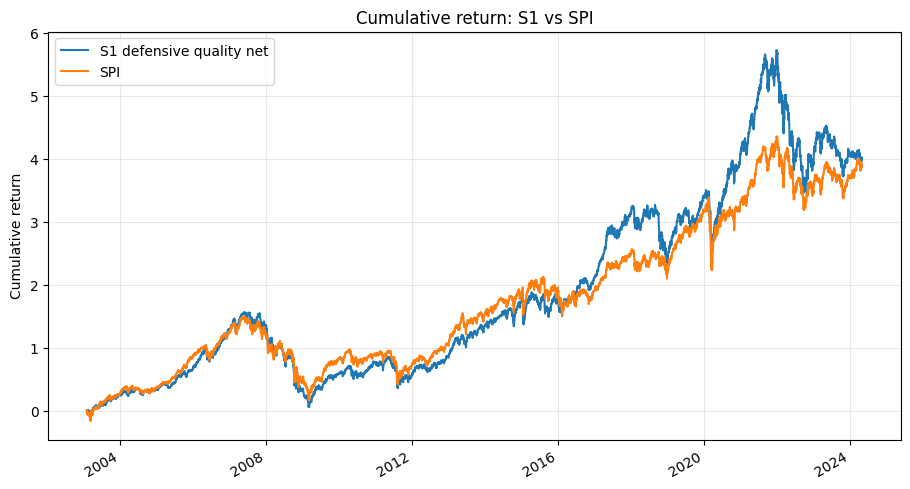

In [9]:
ax = ((1 + comparison).cumprod() - 1).plot(figsize=(11, 6), title='Cumulative return: S1 vs SPI')
ax.set_ylabel('Cumulative return')
ax.grid(alpha=0.3)
plt.show()

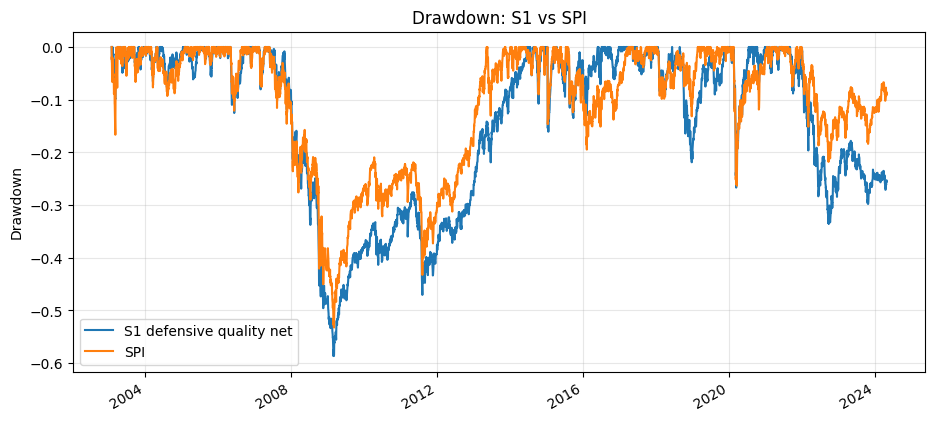

In [10]:
def drawdown(return_df):
    wealth = (1 + return_df).cumprod()
    return wealth / wealth.cummax() - 1


ax = drawdown(comparison).plot(figsize=(11, 5), title='Drawdown: S1 vs SPI')
ax.set_ylabel('Drawdown')
ax.grid(alpha=0.3)
plt.show()

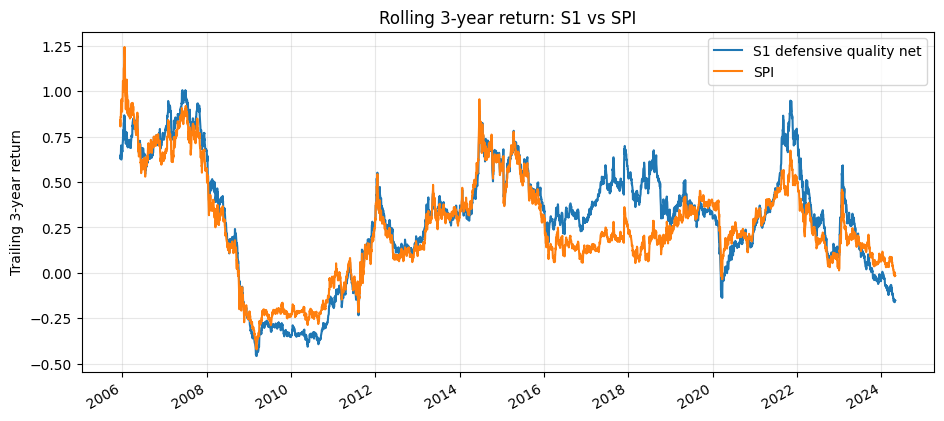

In [11]:
rolling_3y_return = (1 + comparison).rolling(252 * 3).apply(np.prod, raw=True) - 1
ax = rolling_3y_return.plot(figsize=(11, 5), title='Rolling 3-year return: S1 vs SPI')
ax.set_ylabel('Trailing 3-year return')
ax.grid(alpha=0.3)
plt.show()

## 8. Descriptive Statistics

In [12]:
def annualized_return(r, periods_per_year=252):
    r = r.dropna()
    if len(r) == 0:
        return np.nan
    return (1 + r).prod() ** (periods_per_year / len(r)) - 1


def annualized_volatility(r, periods_per_year=252):
    return r.dropna().std() * np.sqrt(periods_per_year)


def max_drawdown(r):
    dd = drawdown(r.to_frame()).iloc[:, 0]
    return dd.min()


def performance_stats(return_df, periods_per_year=252):
    rows = {}
    for col in return_df.columns:
        r = return_df[col].dropna()
        ann_ret = annualized_return(r, periods_per_year)
        ann_vol = annualized_volatility(r, periods_per_year)
        rows[col] = {
            'annualized_return': ann_ret,
            'annualized_volatility': ann_vol,
            'sharpe_rf0': ann_ret / ann_vol if ann_vol != 0 else np.nan,
            'max_drawdown': max_drawdown(r),
            'daily_mean': r.mean(),
            'daily_std': r.std(),
        }
    return pd.DataFrame(rows).T


full_stats = performance_stats(comparison)
last_5y_stats = performance_stats(comparison.loc[comparison.index >= comparison.index.max() - pd.DateOffset(years=5)])

stats = pd.concat({'Full sample': full_stats, 'Last 5 years': last_5y_stats}, axis=0)
stats.style.format('{:.2%}')

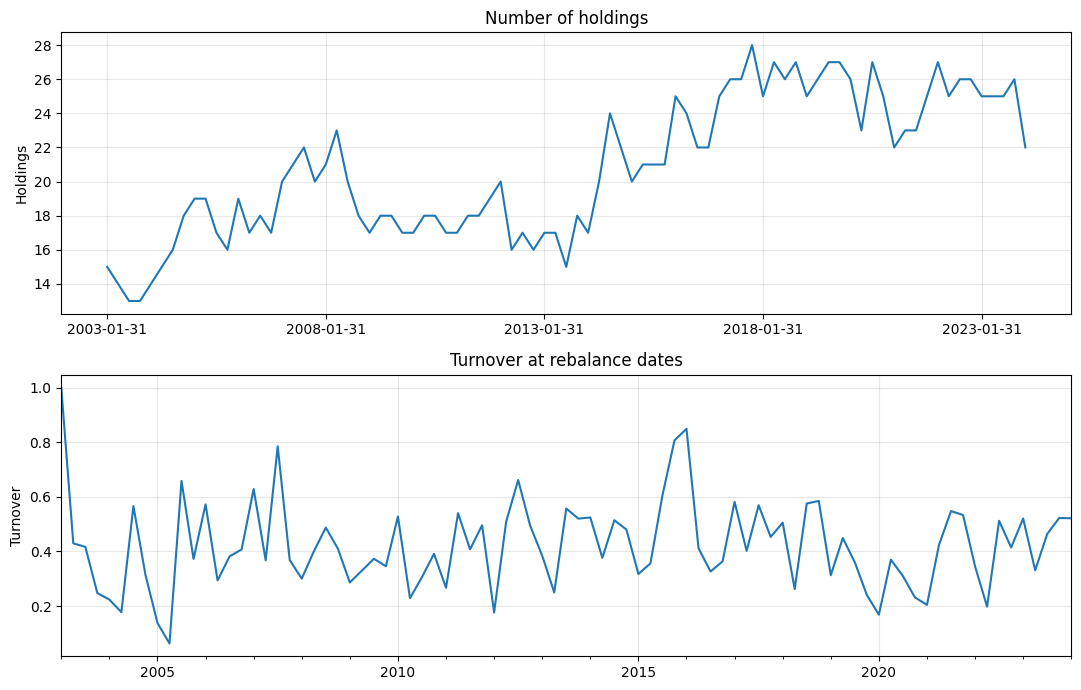

Average turnover: 0.423
Median turnover: 0.408


In [13]:
turnover_s1 = bt_s1.strategy.turnover(return_series=return_series, rescale=False)
turnover_s1.index = pd.to_datetime(turnover_s1.index)
turnover_s1.name = 'turnover'

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=False)
weights_s1.gt(0).sum(axis=1).plot(ax=axes[0], title='Number of holdings')
axes[0].set_ylabel('Holdings')
axes[0].grid(alpha=0.3)
turnover_s1.plot(ax=axes[1], title='Turnover at rebalance dates')
axes[1].set_ylabel('Turnover')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Average turnover:', turnover_s1.mean().round(3))
print('Median turnover:', turnover_s1.median().round(3))

## 9. Selection Diagnostics

This table shows how restrictive the full screening waterfall is through time.

In [14]:
selection_counts = []
for rebdate in rebdates:
    bs_s1.build_selection(rebdate)
    binary = bs_s1.selection.df_binary()
    counts = binary.sum(axis=0).rename(rebdate)
    counts['selected_after_all_filters'] = binary.eq(1).all(axis=1).sum()
    selection_counts.append(counts)

selection_counts = pd.DataFrame(selection_counts)
selection_counts.index = pd.to_datetime(selection_counts.index)
selection_counts.tail()

,return_history,gaps,min_volume,fundamental_freshness,positive_profitability,acceptable_leverage,realized_volatility,quality_floor,selected_after_all_filters
2023-01-31,53.0,53.0,53.0,53.0,53.0,53.0,53.0,27.0,27.0
2023-04-30,53.0,53.0,53.0,53.0,53.0,53.0,53.0,26.0,26.0
2023-07-31,50.0,50.0,50.0,50.0,50.0,50.0,50.0,27.0,27.0
2023-10-31,50.0,50.0,50.0,50.0,50.0,50.0,50.0,28.0,28.0
2024-01-31,47.0,47.0,47.0,47.0,47.0,47.0,47.0,23.0,23.0


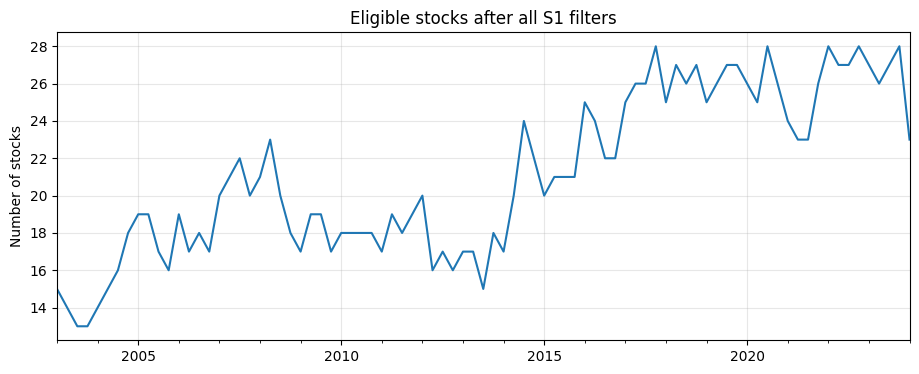

,count,mean,std,min,25%,50%,75%,max
return_history,85.0,41.341176,8.388701,25.0,33.0,41.0,50.0,55.0
gaps,85.0,41.341176,8.388701,25.0,33.0,41.0,50.0,55.0
min_volume,85.0,41.341176,8.388701,25.0,33.0,41.0,50.0,55.0
fundamental_freshness,85.0,41.341176,8.388701,25.0,33.0,41.0,50.0,55.0
positive_profitability,85.0,41.341176,8.388701,25.0,33.0,41.0,50.0,55.0
acceptable_leverage,85.0,41.341176,8.388701,25.0,33.0,41.0,50.0,55.0
realized_volatility,85.0,41.341176,8.388701,25.0,33.0,41.0,50.0,55.0
quality_floor,85.0,21.105882,4.320559,13.0,18.0,20.0,25.0,28.0
selected_after_all_filters,85.0,21.105882,4.320559,13.0,18.0,20.0,25.0,28.0


In [15]:
ax = selection_counts['selected_after_all_filters'].plot(
    figsize=(11, 4),
    title='Eligible stocks after all S1 filters',
)
ax.set_ylabel('Number of stocks')
ax.grid(alpha=0.3)
plt.show()

selection_counts.describe().T

## 10. Interpretation Draft

The S1 strategy is deliberately defensive. It first removes stocks with weak investability, stale fundamentals, weak profitability, high leverage, high volatility, and below-median quality. Only after this economic screening step does the optimizer allocate capital, using a long-only minimum-variance objective with stock and sector caps.

This design should be judged mainly on drawdown, volatility, turnover, and net performance relative to SPI. If it underperforms strongly in bull markets but has lower volatility and smaller drawdowns, that is still consistent with the defensive-compounder thesis. If it does not reduce drawdowns or volatility, the screens and constraints are not adding enough defensive value.